<a href="https://colab.research.google.com/github/mufidrosidi-404/Komputasi-Numerik/blob/main/materi-B-bisection/Bisection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Metode Bisection (Belah Dua) untuk Persamaan Non Linear

**Mata kuliah:** Komputasi Numerik  
**Nama:** Mufid Rosidi  
**NIM:** 202511420044  
**Materi B:** Persamaan Non Linear, metode Bisection

Notebook ini mencari akar persamaan non linear dengan cara membelah selang berulang kali.
Aku memakai fungsi uji yang kususun sendiri, lengkap dengan pemeriksaan tanda *f(kiri) × f(kanan) < 0*,
toleransi, batas putaran, dan tabel iterasi. Jalankan dari **Cell 1 sampai Cell 9**, satu per satu.

### Cell 1 · Siapkan perkakas

In [ ]:
import math
import matplotlib.pyplot as plt
print("Perkakas siap.")

Perkakas siap.


### Cell 2 · Tentukan fungsi uji dan pengaturannya


In [ ]:
def fungsi_uji(x):
    return x**3 - 7*x + 2*math.sin(x) - 1.7

ujung_kiri = 2.0
ujung_kanan = 4.0
ambang_galat = 1e-6
jatah_putaran = 60

print("Persamaan : f(x) = x^3 - 7x + 2 sin(x) - 1,7")
print(f"Selang    : [{ujung_kiri}, {ujung_kanan}]")
print(f"Toleransi : {ambang_galat}  |  Batas iterasi : {jatah_putaran}")

Persamaan : f(x) = x^3 - 7x + 2 sin(x) - 1,7
Selang    : [2.0, 4.0]
Toleransi : 1e-06  |  Batas iterasi : 60


### Cell 3 · Pemeriksa tanda (apakah selang mengapit akar?)


In [ ]:
def selang_mengapit_akar(f, kiri, kanan):
    nilai_kiri = f(kiri)
    nilai_kanan = f(kanan)
    print(f"f({kiri}) = {nilai_kiri:.6f}  |  f({kanan}) = {nilai_kanan:.6f}")
    hasil_kali = nilai_kiri * nilai_kanan
    print(f"f(kiri) x f(kanan) = {hasil_kali:.6f}")
    return hasil_kali < 0

### Cell 4 · Mesin belah dua


In [ ]:
def belah_dua_ku(f, kiri, kanan, ambang, jatah):
    if not selang_mengapit_akar(f, kiri, kanan):
        raise ValueError("Selang tidak mengapit akar: f(kiri) dan f(kanan) bertanda sama.")
    catatan = []
    nilai_kiri = f(kiri)
    konvergen = False
    for putaran in range(1, jatah + 1):
        tengah = (kiri + kanan) / 2
        nilai_tengah = f(tengah)
        batas_galat = (kanan - kiri) / 2
        catatan.append((putaran, kiri, kanan, tengah, nilai_kiri, nilai_tengah, batas_galat))
        if nilai_tengah == 0 or batas_galat < ambang:
            konvergen = True
            break
        if nilai_kiri * nilai_tengah < 0:
            kanan = tengah
        else:
            kiri = tengah
            nilai_kiri = nilai_tengah
    return tengah, catatan, konvergen

### Cell 5 · Perkiraan jumlah putaran (teori)


In [ ]:
lebar_awal = ujung_kanan - ujung_kiri
k_teori = math.floor(math.log2(lebar_awal / ambang_galat)) + 1
print(f"Lebar selang awal              : {lebar_awal}")
print(f"Perkiraan jumlah putaran (teori): {k_teori}")

Lebar selang awal              : 2.0
Perkiraan jumlah putaran (teori): 21


### Cell 6 · Jalankan dan lihat tabel iterasi


In [ ]:
akar_taksiran, tabel, berhasil = belah_dua_ku(fungsi_uji, ujung_kiri, ujung_kanan, ambang_galat, jatah_putaran)

print("\n  Ke |    kiri    |   kanan    |   tengah   |  f(kiri)   | f(tengah)  | batas galat")
print("-" * 85)
for (ke, ki, ka, te, fk, ft, bg) in tabel:
    print(f"{ke:4d} | {ki:10.6f} | {ka:10.6f} | {te:10.6f} | {fk:10.5f} | {ft:10.5f} | {bg:.2e}")

print(f"\nBerhenti karena toleransi tercapai? {berhasil}")
print(f"Jumlah putaran sebenarnya        : {len(tabel)} (teori: {k_teori})")
print(f"Taksiran akar                    : {akar_taksiran:.6f}")

f(2.0) = -5.881405  |  f(4.0) = 32.786395
f(kiri) x f(kanan) = -192.830072

  Ke |    kiri    |   kanan    |   tengah   |  f(kiri)   | f(tengah)  | batas galat
-------------------------------------------------------------------------------------
   1 |   2.000000 |   4.000000 |   3.000000 |   -5.88141 |    4.58224 | 1.00e+00
   2 |   2.000000 |   3.000000 |   2.500000 |   -5.88141 |   -2.37806 | 5.00e-01
   3 |   2.500000 |   3.000000 |   2.750000 |   -2.37806 |    0.61020 | 2.50e-01
   4 |   2.500000 |   2.750000 |   2.625000 |   -2.37806 |   -0.99927 | 1.25e-01
   5 |   2.625000 |   2.750000 |   2.687500 |   -0.99927 |   -0.22432 | 6.25e-02
   6 |   2.687500 |   2.750000 |   2.718750 |   -0.22432 |    0.18538 | 3.12e-02
   7 |   2.687500 |   2.718750 |   2.703125 |   -0.22432 |   -0.02135 | 1.56e-02
   8 |   2.703125 |   2.718750 |   2.710938 |   -0.02135 |    0.08154 | 7.81e-03
   9 |   2.703125 |   2.710938 |   2.707031 |   -0.02135 |    0.02998 | 3.91e-03
  10 |   2.703125 |   2.7

### Cell 7 · Cek hasil


In [ ]:
print(f"f(akar taksiran) = {fungsi_uji(akar_taksiran):.3e}")
try:
    from scipy.optimize import brentq
    akar_pembanding = brentq(fungsi_uji, ujung_kiri, ujung_kanan, xtol=1e-12)
    selisih = abs(akar_taksiran - akar_pembanding)
    print(f"Akar pembanding (SciPy) = {akar_pembanding:.8f}")
    print(f"Selisih                 = {selisih:.3e}")
    print("Selisih lebih kecil dari toleransi?", selisih < ambang_galat)
except ImportError:
    print("SciPy tidak tersedia, lewati pembandingan.")

f(akar taksiran) = -9.844e-06
Akar pembanding (SciPy) = 2.70475176
Selisih                 = 7.494e-07
Selisih lebih kecil dari toleransi? True


### Cell 8 · Uji selang yang salah


In [ ]:
try:
    belah_dua_ku(fungsi_uji, 3.5, 5.0, ambang_galat, jatah_putaran)
except ValueError as galat:
    print("Program menolak dengan pesan:", galat)

### Cell 9 · Grafik fungsi dan akarnya


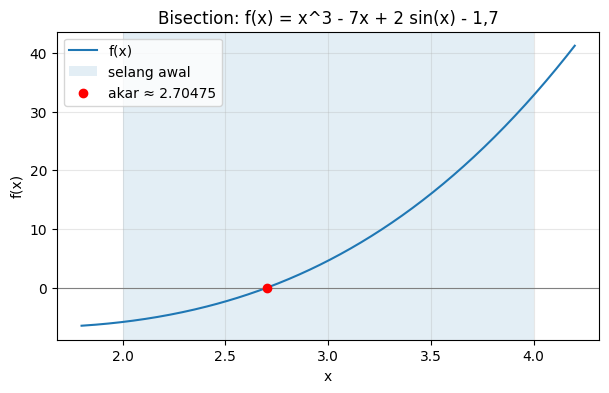

In [ ]:
titik_x = [1.8 + i * 0.01 for i in range(0, 241)]
titik_y = [fungsi_uji(x) for x in titik_x]
plt.figure(figsize=(7, 4))
plt.plot(titik_x, titik_y, label="f(x)")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvspan(ujung_kiri, ujung_kanan, alpha=0.12, label="selang awal")
plt.scatter([akar_taksiran], [0], color="red", zorder=5, label=f"akar ≈ {akar_taksiran:.5f}")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Bisection: f(x) = x^3 - 7x + 2 sin(x) - 1,7")
plt.legend()
plt.grid(alpha=0.3)
plt.show()